# ICT4403 Assignment 3: English → Hindi machine translation
Basic Transformer, mT5-small, LLaMA 3.2 1B, Gemma 3 1B on OPUS-100 en-hi.

**Before running:** Settings → Accelerator **GPU T4 x2**, Internet **On**, Add-ons → Secrets → `HF_TOKEN` (attached to this notebook).
Run cells top to bottom (or Save Version → *Save & Run All* to run in the background without keeping the tab open).

In [1]:
from pathlib import Path
import os, subprocess, sys, shutil, threading, time

repo = Path('/kaggle/working/generative-ai-machine-translation')
if not repo.exists():
    subprocess.run(['git','clone','https://github.com/saishthakur/generative-ai-machine-translation.git',str(repo)],check=True)
os.chdir(repo)
print('repo:', Path.cwd())

Cloning into '/kaggle/working/generative-ai-machine-translation'...


repo: /kaggle/working/generative-ai-machine-translation


In [2]:
%pip install -q 'transformers>=4.50,<6' 'datasets>=3.0' 'sentencepiece>=0.2' 'sacrebleu>=2.4' 'accelerate>=0.34'

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
n_gpu = torch.cuda.device_count()
print('CUDA:', torch.cuda.is_available(), '| GPUs:', n_gpu)
if n_gpu < 1:
    raise RuntimeError('No GPU. Settings -> Accelerator -> GPU T4 x2, then restart the session.')
if n_gpu < 2:
    print('WARNING: only 1 GPU. Everything will share GPU 0 and run slower.')

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download
login(token=UserSecretsClient().get_secret('HF_TOKEN'), add_to_git_credential=False)

# Pre-flight: fail now (not hours later) if gated model access is missing.
for m in ['meta-llama/Llama-3.2-1B-Instruct', 'google/gemma-3-1b-it']:
    hf_hub_download(m, 'config.json'); print('access OK:', m)
print('free disk (GB):', shutil.disk_usage('/kaggle/working').free // 2**30)

CUDA: True | GPUs: 2


config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

access OK: meta-llama/Llama-3.2-1B-Instruct


config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

access OK: google/gemma-3-1b-it
free disk (GB): 19


In [4]:
# Optional restore after a session restart: set PREV to an attached notebook-output path, e.g. '/kaggle/input/<name>/outputs'
PREV = ''
if PREV and Path(PREV).exists() and not Path('outputs').exists():
    shutil.copytree(PREV, 'outputs'); print('restored from', PREV)

def backup():
    # zip outputs (without bulky training checkpoints) into /kaggle/working so it shows in the Output panel
    import tempfile
    tmp = Path(tempfile.mkdtemp(dir='/kaggle/working')) / 'outputs'
    shutil.copytree('outputs', tmp, ignore=shutil.ignore_patterns('checkpoint-*'))
    print(shutil.make_archive('/kaggle/working/backup_outputs', 'zip', tmp)); shutil.rmtree(tmp.parent)

## 1. Data (20k train / 1k validation / 1k test, seed 4403)

In [5]:
r = subprocess.run([sys.executable, 'scripts/prepare_data.py', '--train-rows','20000','--validation-rows','1000','--test-rows','1000','--seed','4403'],
                   capture_output=True, text=True)
print(r.stdout[-1500:]);
if r.returncode: raise RuntimeError('prepare_data failed:\n' + r.stderr[-3000:])
import pandas as pd
for n in ['train','validation','test']:
    df = pd.read_csv(f'data/processed/{n}.csv'); print(n, df.shape, list(df.columns))

train: wrote 20000 sentence pairs to data/processed
validation: wrote 1000 sentence pairs to data/processed
test: wrote 1000 sentence pairs to data/processed
Dataset: Helsinki-NLP/opus-100 (en-hi); seed=4403
Keep data/processed local unless the dataset terms explicitly allow redistribution.

train (20000, 2) ['source', 'target']
validation (1000, 2) ['source', 'target']
test (1000, 2) ['source', 'target']


## 2. Run everything (both GPUs busy the whole time)
GPU 0: Transformer train → eval → LLaMA (T=0, 0.3, 0.7)
GPU 1: mT5 train → eval → Gemma (T=0, 0.3, 0.7)

Every 30 s you get a status block: the job running on each GPU, elapsed time, the last log line, and live GPU utilisation/memory. A GPU idle (<5%) while a job is "running" for ~2 min triggers a warning. Notes:
* `evaluate.py` prints nothing until it finishes, so for LLaMA/Gemma judge by **GPU util** (high = working).
* Finished jobs are skipped if you rerun the cell. Training checkpoints are deleted after each training job (disk).
* A job that runs out of GPU memory is retried automatically with half the batch size.
* A failed job does not stop the other queued jobs; the cell raises at the end listing what failed. Logs: `/kaggle/working/log_<job>.txt`.

In [6]:
def gpu_stats():
    try:
        out = subprocess.run(['nvidia-smi','--query-gpu=index,utilization.gpu,memory.used,memory.total','--format=csv,noheader,nounits'],
                             capture_output=True, text=True).stdout.strip().splitlines()
        return {int(r.split(',')[0]): tuple(int(x) for x in r.split(',')) [1:] for r in out}
    except Exception:
        return {}

def log_tail(path, n=400):
    try:
        return Path(path).read_bytes()[-n:].decode('utf-8', 'replace')
    except Exception:
        return ''

def run_chains(chains, poll=30):
    # chains: {gpu: [(name, args, skip_if), ...]}; each chain runs its jobs in order on its own GPU; chains run concurrently.
    state = {g: {'job': None, 'start': None, 'log': None, 'proc': None, 'note': '', 'done': [], 'failed': []} for g in chains}

    def worker(g, jobs):
        st = state[g]
        for name, args, skip_if in jobs:
            if skip_if and list(Path('.').glob(skip_if)):
                st['done'].append(name + ' (skipped)'); continue
            args = list(args); st['note'] = ''; st['log'] = Path(f'/kaggle/working/log_{name}.txt')
            st['job'] = name; st['start'] = time.time(); ok = False; tries = 0
            while True:
                env = os.environ.copy(); env['CUDA_VISIBLE_DEVICES'] = str(g if n_gpu > 1 else 0); env['PYTHONUNBUFFERED'] = '1'
                with open(st['log'], 'wb') as f:
                    st['proc'] = subprocess.Popen([sys.executable] + args, env=env, stdout=f, stderr=subprocess.STDOUT)
                    rc = st['proc'].wait()
                if rc == 0:
                    ok = True; break
                oom = 'out of memory' in log_tail(st['log'], 6000).lower()
                if oom and tries < 2 and '--batch-size' in args:
                    i = args.index('--batch-size') + 1; new = max(1, int(args[i]) // 2)
                    if new == int(args[i]): break
                    st['note'] = f'  (OOM -> retrying with batch {new})'; args[i] = str(new); tries += 1
                    continue
                break
            if ok:
                st['done'].append(name)
                if name.startswith('train_') and skip_if:           # free disk: drop per-epoch checkpoints of THIS model only
                    for c in Path(skip_if).parent.glob('checkpoint-*'): shutil.rmtree(c, ignore_errors=True)
            else:
                st['failed'].append(name)
        st['job'] = None

    threads = {g: threading.Thread(target=worker, args=(g, jobs), daemon=True) for g, jobs in chains.items()}
    for t in threads.values(): t.start()
    idle = {g: 0 for g in chains}; t0 = time.time()
    try:
        while any(t.is_alive() for t in threads.values()):
            time.sleep(poll)
            gs = gpu_stats()
            print(f'--- {time.strftime("%H:%M:%S")} | total elapsed {(time.time()-t0)/60:.0f} min ---')
            for g, st in state.items():
                if st['job']:
                    seg = log_tail(st['log']).replace('\r', '\n').strip().splitlines()
                    tail = seg[-1][:140] if seg else '(no output yet)'
                    u, mu, mt = gs.get(g if n_gpu > 1 else 0, (0, 0, 0))
                    idle[g] = idle[g] + 1 if u < 5 else 0
                    warn = '  <<< WARNING: GPU idle, job may be stuck' if idle[g] >= 4 else ''
                    print(f'GPU{g} RUNNING {st["job"]:<18} {(time.time()-st["start"])/60:5.1f} min | util {u:3d}% mem {mu}/{mt} MB{st["note"]}{warn}\n      log: {tail}')
                else:
                    print(f'GPU{g} chain finished | done {len(st["done"])} | failed {st["failed"]}')
    except BaseException:
        for st in state.values():                                  # cell interrupted: do not leave orphan jobs on the GPUs
            if st['proc'] and st['proc'].poll() is None: st['proc'].terminate()
        raise
    for g, st in state.items():
        print(f'GPU{g} done: {st["done"]}')
    failed = [n for st in state.values() for n in st['failed']]
    if failed:
        for n in failed: print(f'\n===== log_{n}.txt (end) =====\n' + log_tail(f'/kaggle/working/log_{n}.txt', 2500))
        raise RuntimeError(f'failed jobs: {failed} (see logs above)')

def llm_chain(prefix, model):
    return [(f'{prefix}_{tag}',
             ['scripts/evaluate.py','--architecture','causal','--model',model,'--batch-size','8','--max-input-length','256',
              '--max-new-tokens','128','--temperature',t,'--output-dir',f'outputs/evaluation/{prefix}-{tag}'],
             f'outputs/evaluation/{prefix}-{tag}/*_metrics.json') for t, tag in [('0','t0'),('0.3','t03'),('0.7','t07')]]

def seq2seq_eval(name, d):
    return (f'eval_{name}',
            ['scripts/evaluate.py','--architecture','seq2seq','--model',f'outputs/{d}','--batch-size','32','--max-input-length','256',
             '--max-new-tokens','256','--output-dir',f'outputs/evaluation/{d}'], f'outputs/evaluation/{d}/*_metrics.json')

run_chains({
  0: [('train_transformer', ['scripts/train_basic_transformer.py','--epochs','3','--batch-size','16','--max-length','256'],
       'outputs/basic-transformer/config.json'),
      seq2seq_eval('transformer','basic-transformer')] + llm_chain('llama','meta-llama/Llama-3.2-1B-Instruct'),
  1: [('train_mt5', ['scripts/train_pretrained.py','--architecture','seq2seq','--model','google/mt5-small','--output-dir','outputs/mt5-small',
                     '--epochs','3','--batch-size','8','--max-length','256','--learning-rate','3e-4'], 'outputs/mt5-small/config.json'),
      seq2seq_eval('mt5','mt5-small')] + llm_chain('gemma','google/gemma-3-1b-it'),
})
backup()

--- 04:29:26 | total elapsed 1 min ---
GPU0 RUNNING train_transformer    0.5 min | util   0% mem 3/15360 MB
      log: Tokenizing parallel text:  50%|█████     | 10000/20000 [00:03<00:04, 2343.86 examples/s]
GPU1 RUNNING train_mt5            0.5 min | util   0% mem 3/15360 MB
      log: (no output yet)
--- 04:29:56 | total elapsed 1 min ---
GPU0 RUNNING train_transformer    1.0 min | util  82% mem 1425/15360 MB
      log:   4%|▍         | 152/3750 [00:17<06:23,  9.39it/s]
GPU1 RUNNING train_mt5            1.0 min | util 100% mem 10717/15360 MB
      log:   0%|          | 28/7500 [00:09<44:48,  2.78it/s]
--- 04:30:26 | total elapsed 2 min ---
GPU0 RUNNING train_transformer    1.5 min | util  93% mem 1425/15360 MB
      log:  12%|█▏        | 433/3750 [00:47<06:13,  8.89it/s]
GPU1 RUNNING train_mt5            1.5 min | util  91% mem 12095/15360 MB
      log:   2%|▏         | 124/7500 [00:39<39:28,  3.11it/s]
--- 04:30:56 | total elapsed 2 min ---
GPU0 RUNNING train_transformer    2.0 min 

## 3. Results table and plot

In [7]:
r = subprocess.run([sys.executable, 'scripts/summarize_results.py', '--outputs-dir','outputs','--output','outputs/results_summary.csv'], capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-1500:])
res = pd.read_csv('outputs/results_summary.csv'); display(res)

Wrote 8 run rows to outputs/results_summary.csv
 


,model,architecture,temperature,test_examples,bleu,chrf,inference_seconds,seconds_per_example,training_seconds,parameter_count,device,batch_size,max_input_length,max_new_tokens,sacrebleu_version
0,outputs/basic-transformer,seq2seq,0.0,1000,0.303523,8.120815,60.537321,0.060537,434.83748684600005,7411456,cuda,32,256,256,2.6.0
1,google/gemma-3-1b-it,causal,0.0,1000,1.085763,13.483056,1524.575950,1.524576,N/A if prompted,999885952,cuda,8,256,128,2.6.0
2,google/gemma-3-1b-it,causal,0.3,1000,1.068315,13.488173,1613.180386,1.613180,N/A if prompted,999885952,cuda,8,256,128,2.6.0
3,google/gemma-3-1b-it,causal,0.7,1000,1.064446,13.337489,1614.434477,1.614434,N/A if prompted,999885952,cuda,8,256,128,2.6.0
4,meta-llama/Llama-3.2-1B-Instruct,causal,0.0,1000,4.031620,22.523893,1367.782314,1.367782,N/A if prompted,1235814400,cuda,8,256,128,2.6.0
5,meta-llama/Llama-3.2-1B-Instruct,causal,0.3,1000,3.955735,22.490021,1421.188545,1.421189,N/A if prompted,1235814400,cuda,8,256,128,2.6.0
6,meta-llama/Llama-3.2-1B-Instruct,causal,0.7,1000,3.170107,21.271675,1429.324471,1.429324,N/A if prompted,1235814400,cuda,8,256,128,2.6.0
7,outputs/mt5-small,seq2seq,0.0,1000,4.796941,19.205818,136.256583,0.136257,2811.655620783,300176768,cuda,32,256,256,2.6.0


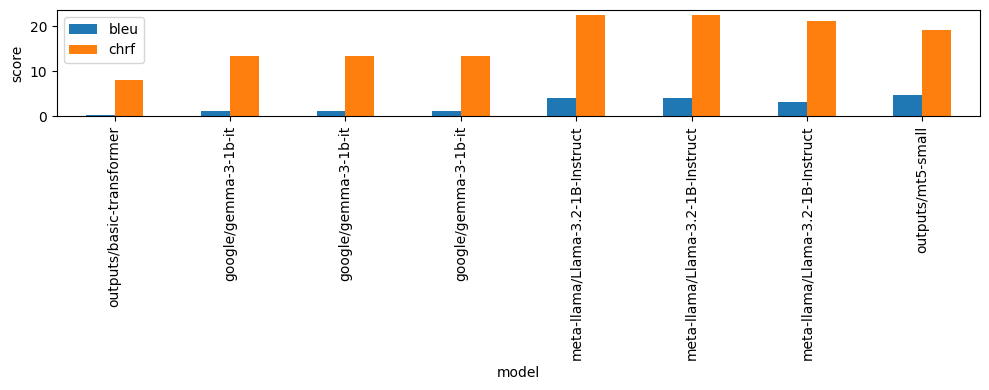

In [8]:
import matplotlib.pyplot as plt
cols = [c for c in res.columns if c.lower() in ('bleu','chrf')]
if cols:
    ax = res.set_index(res.columns[0])[cols].plot.bar(figsize=(10,4)); ax.set_ylabel('score'); plt.tight_layout()
    plt.savefig('outputs/scores.png', dpi=150); plt.show()
else:
    print('Columns are', list(res.columns), '- edit the names above to plot them')

## 4. Sample translations (for the responsible-AI discussion)

In [9]:
import glob
for f in sorted(glob.glob('outputs/evaluation/*/*predictions.csv')):
    print('====', f); display(pd.read_csv(f).head(5))

==== outputs/evaluation/basic-transformer/basic-transformer_predictions.csv


,source,reference,prediction
0,"Give shots of injections or pills, but he must...",सुई लगाओ या गोली खिलाओ लेकिन इसे जल्दी से ठीक ...,और जिसे को को सारे के को को कि सारारे के करारा...
1,"They said, “O Shuaib, we do not understand muc...",और वह लोग कहने लगे ऐ शुएब जो बाते तुम कहते हो ...,और जब को जिन को जिने को को जिसे को को जाने को ...
2,- Yeah.,- हाँ.,मैं के है.
3,If evil befalls him he is perturbed;,"जि उसे तकलीफ़ पहुँचती है तो घबरा उठता है,",और को में को सारे के सारे के किया है करारे है ...
4,♪ BE FOREVER BOUND,♪हमेशाके लिएबाध्यहोने,संप्रितार्तारार्ताराक


==== outputs/evaluation/gemma-t0/gemma-3-1b-it_predictions.csv


,source,reference,prediction
0,"Give shots of injections or pills, but he must...",सुई लगाओ या गोली खिलाओ लेकिन इसे जल्दी से ठीक ...,Here are a few options for translating “Give s...
1,"They said, “O Shuaib, we do not understand muc...",और वह लोग कहने लगे ऐ शुएब जो बाते तुम कहते हो ...,Here are a few options for translating that pa...
2,- Yeah.,- हाँ.,"The most common and natural translation of ""Ye..."
3,If evil befalls him he is perturbed;,"जि उसे तकलीफ़ पहुँचती है तो घबरा उठता है,",Here are a few options for translating “If evi...
4,♪ BE FOREVER BOUND,♪हमेशाके लिएबाध्यहोने,The most common and fitting translation of “BE...


==== outputs/evaluation/gemma-t03/gemma-3-1b-it_predictions.csv


,source,reference,prediction
0,"Give shots of injections or pills, but he must...",सुई लगाओ या गोली खिलाओ लेकिन इसे जल्दी से ठीक ...,Here are a few options for translating “Give s...
1,"They said, “O Shuaib, we do not understand muc...",और वह लोग कहने लगे ऐ शुएब जो बाते तुम कहते हो ...,Here are a few options for translating that pa...
2,- Yeah.,- हाँ.,"The most common and natural translation of ""Ye..."
3,If evil befalls him he is perturbed;,"जि उसे तकलीफ़ पहुँचती है तो घबरा उठता है,",Here are a few options for translating “If evi...
4,♪ BE FOREVER BOUND,♪हमेशाके लिएबाध्यहोने,The most common and natural translation of “BE...


... (6 outputs left out)

==== outputs/evaluation/llama-t07/Llama-3.2-1B-Instruct_predictions.csv


,source,reference,prediction
0,"Give shots of injections or pills, but he must...",सुई लगाओ या गोली खिलाओ लेकिन इसे जल्दी से ठीक ...,"मुझे दिखाने के लिए गोलियाँ या इंजेक्शन दें, ले..."
1,"They said, “O Shuaib, we do not understand muc...",और वह लोग कहने लगे ऐ शुएब जो बाते तुम कहते हो ...,"उन्होंने कहा, ""ओ शुआब, हमें आपको समझने में बहु..."
2,- Yeah.,- हाँ.,अरे
3,If evil befalls him he is perturbed;,"जि उसे तकलीफ़ पहुँचती है तो घबरा उठता है,",यदि कठिनाई (या बुराई) उसके ऊपर हो तो वह डर जात...
4,♪ BE FOREVER BOUND,♪हमेशाके लिएबाध्यहोने,बीवी फॉरेवर बाउंड


==== outputs/evaluation/mt5-small/mt5-small_predictions.csv


,source,reference,prediction
0,"Give shots of injections or pills, but he must...",सुई लगाओ या गोली खिलाओ लेकिन इसे जल्दी से ठीक ...,"और नबी के लिए ऊँची या नबी का ऊँची दें, किन्तु ..."
1,"They said, “O Shuaib, we do not understand muc...",और वह लोग कहने लगे ऐ शुएब जो बाते तुम कहते हो ...,"और उन लोगों ने कहा, ""ऐ ईबराहीम! हम तुम्हारे पा..."
2,- Yeah.,- हाँ.,- हाँ.
3,If evil befalls him he is perturbed;,"जि उसे तकलीफ़ पहुँचती है तो घबरा उठता है,",यदि वह उसकी तसबीह होगी तो उसे डरानेवाला होगा
4,♪ BE FOREVER BOUND,♪हमेशाके लिएबाध्यहोने,♪ अब ही नबी हो जाओ


## 5. Package results (no checkpoints or dataset)

In [10]:
bundle = Path('/kaggle/working/bundle'); shutil.rmtree(bundle, ignore_errors=True)
out = Path('outputs')
for pat in ['**/*_metrics.json','**/training_metrics.json','evaluation/**/*_predictions.csv','results_summary.csv','scores.png']:
    for p in out.glob(pat):
        d = bundle / p.relative_to(out); d.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, d)
print(shutil.make_archive('/kaggle/working/assignment_results','zip',bundle))

/kaggle/working/assignment_results.zip
